# Clasificación de textos: toxicidad en mensajes sobre protestas
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Noviembre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/4_clasificacion_TADA.ipynb)

**Sesión 12 · jueves 12 de noviembre de 2026 · Parte 2: demostración.**

¿Es tóxico este mensaje? Construimos y validamos un clasificador de toxicidad para mensajes en español con todo lo visto en las Sesiones 8 a 10 (*pipelines*, validación cruzada, F1 macro, búsqueda de hiperparámetros), ahora con **texto**. Los datos son un patrón oro (*gold standard*) codificado por personas: mensajes de Twitter (hoy X) sobre protestas en Argentina y Chile. Al final probamos el modelo **fuera de su dominio**, con mensajes sobre el proceso constitucional chileno. Cada sección corresponde a una tarjeta de la presentación:

| N.º | Sección | Presentación |
|---|---|---|
| 1 | Datos: el patrón oro y la partición | Caso de administración pública: toxicidad en protestas |
| 2 | Preprocesamiento: tokenización, palabras vacías, *stemming* y lematización | Tokenización; Palabras vacías (1) y (2); *Stemming* y lematización |
| 3 | Representaciones: bolsa de palabras, TF-IDF y n-gramas | Bolsa de palabras y TF-IDF; n-gramas y datos dispersos |
| 4 | Clasificación: Naive Bayes, SVM lineal y regresión logística | Aprendizaje supervisado con texto |
| 5 | Interpretación: términos informativos y análisis de errores | Aprendizaje supervisado con texto |
| 6 | Fuera del dominio: la Convención Constitucional | Cuatro principios (validar, validar, validar) |
| 7 | Ejercicios | No aplica |
| A | Anexo: Ridge y Lasso (notebook de 2025) | No aplica |

**Cómo usarlo.**
- Las celdas precedidas por **▶ En vivo** se ejecutan durante la clase. El resto queda para la revisión autónoma.
- Todo el notebook corre de principio a fin en la CPU de un computador portátil en menos de 2 minutos. Descarga dos archivos pequeños de Hugging Face (menos de 1 MB cada uno) y, la primera vez, la lista de palabras vacías de NLTK.
- Las versiones de las librerías están fijadas en el archivo `requirements.txt` del repositorio del curso, que en esta sesión agrega spaCy, su modelo para español y NLTK.
- `random_state=86` en todos los pasos aleatorios, para que los resultados sean reproducibles.
- Reglas de esta sesión (como en S9 y S10): los hiperparámetros se eligen con **validación cruzada dentro del entrenamiento**; el conjunto de prueba se usa **una sola vez**, al final de la sección 4.

**Advertencia de contenido:** algunos mensajes y términos de la sección 5 contienen lenguaje ofensivo. Son datos de investigación; las menciones a usuarios se reemplazan por `@usuario`.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo lo que falte, sin actualizar los paquetes preinstalados, así que no hace falta reiniciar la sesión. spaCy y NLTK ya vienen en Colab; falta el **modelo de spaCy para español** (`es_core_news_sm`, unos 13 MB), que instala la segunda celda. Los datos se descargan de fuentes públicas. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt` (incluye el modelo de spaCy).

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2, NumPy ≥ 2.0, spaCy ≥ 3.7 y NLTK ≥ 3.8. Con versiones distintas de las de `requirements.txt`, algunos resultados pueden cambiar levemente.

En Colab, `%pip` puede mostrar "Note: you may need to restart the kernel to use updated packages". No hace falta reiniciar: el modelo de spaCy es un paquete nuevo, no una actualización.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
    "spacy": ("spacy", "3.7"),
    "nltk": ("nltk", "3.8"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | spacy 3.8.16 | nltk 3.10.3 | computador local


In [2]:
## Modelo de spaCy para español: es_core_news_sm 3.8.0 (compatible con spaCy 3.8; unos 13 MB)
MODELO_SPACY = "es_core_news_sm"
URL_MODELO = ("https://github.com/explosion/spacy-models/releases/download/"
              "es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl")
if find_spec(MODELO_SPACY) is None:
    if EN_COLAB:
        ## En Colab se instala desde la página oficial de modelos de spaCy (no actualiza nada)
        get_ipython().run_line_magic("pip", "install -q " + URL_MODELO)
        invalidate_caches()
    else:
        raise ModuleNotFoundError(f"Falta {MODELO_SPACY}. Instálelo con pip install -r requirements.txt.")
print(f"{MODELO_SPACY} {version(MODELO_SPACY)}")

es_core_news_sm 3.8.0


In [3]:
## Importar librerías necesarias
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from scipy.stats import loguniform
from spacy.lang.es.stop_words import STOP_WORDS as STOP_SPACY
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.metrics import (
    f1_score, cohen_kappa_score, classification_report, ConfusionMatrixDisplay, r2_score
)

## Lista de palabras vacías de NLTK (se descarga una vez, unos pocos KB)
nltk.download("stopwords", quiet=True)

## Versiones (en su computador, las de requirements.txt; en Colab, las preinstaladas)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"spacy {spacy.__version__} | nltk {nltk.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | spacy 3.8.16 | nltk 3.10.3


In [4]:
## Estilo de los gráficos (el mismo de S8 a S10) y número de procesos para la búsqueda
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
N_PROCESOS = min(8, os.cpu_count())

## 1. Datos: el patrón oro de toxicidad

**▶ En vivo.** El conjunto `toxicity-protests-ES` (Hugging Face, licencia CC BY 4.0) es el patrón oro de González-Bustamante (2024, sección 3.1):
- **1.000 mensajes** de Twitter sobre protestas: 500 de Argentina (agosto de 2020, contra las medidas por el coronavirus y una reforma judicial) y 500 de Chile (estallido social de octubre de 2019). Los mensajes se recolectaron por *hashtags*, así que todos tienen al menos uno.
- La muestra está **balanceada** por quintiles del puntaje de toxicidad de un clasificador automático, para que haya mensajes de todos los niveles.
- Un equipo de **cinco codificadores** clasificó cada mensaje como TÓXICO ("comentarios groseros, irrespetuosos o poco razonables que probablemente hagan que alguien abandone la discusión") o NO TÓXICO. Cada mensaje fue codificado por **dos** codificadores distintos: columnas `coder_1` y `coder_2` (1 = tóxico).

Usamos `coder_1` como etiqueta, como en los notebooks de 2025 y en la Sesión 13, y `coder_2` como referencia humana.

El archivo se lee directamente desde Hugging Face con su URL pública. Con el paquete `huggingface_hub` instalado, también funciona `pd.read_csv("hf://datasets/bgonzalezbustamante/toxicity-protests-ES/goldstd_protests.csv")`.

In [5]:
## Cargar el patrón oro desde Hugging Face (URL pública del archivo)
URL_HF = "https://huggingface.co/datasets/bgonzalezbustamante/{}/resolve/main/{}"
protestas = pd.read_csv(URL_HF.format("toxicity-protests-ES", "goldstd_protests.csv"))

print(f"{len(protestas):,} mensajes | {protestas.shape[1]} columnas")
print("Mensajes por país:", protestas["country"].value_counts().to_dict())
print("Largo de los mensajes (caracteres): mediana =", int(protestas["text"].str.len().median()),
      "| máximo =", protestas["text"].str.len().max())

## Proporción de mensajes tóxicos según cada codificador, por país
(protestas.groupby("country")[["coder_1", "coder_2"]].mean()
 .rename(columns={"coder_1": "Tóxicos (coder_1)", "coder_2": "Tóxicos (coder_2)"}).round(3))

1,000 mensajes | 39 columnas
Mensajes por país: {'Argentina': 500, 'Chile': 500}
Largo de los mensajes (caracteres): mediana = 140 | máximo = 304


,Tóxicos (coder_1),Tóxicos (coder_2)
country,,
Argentina,0.486,0.470
Chile,0.582,0.574


In [6]:
## Acuerdo entre los dos codificadores: la "verdad" también tiene error
acuerdo = pd.crosstab(protestas["coder_1"], protestas["coder_2"],
                      rownames=["coder_1"], colnames=["coder_2"])
print(f"Acuerdo simple: {(protestas['coder_1'] == protestas['coder_2']).mean():.1%}")
print(f"κ de Cohen: {cohen_kappa_score(protestas['coder_1'], protestas['coder_2']):.3f}")
print(f"F1 macro de coder_2 frente a coder_1: "
      f"{f1_score(protestas['coder_1'], protestas['coder_2'], average='macro'):.3f}")
acuerdo

Acuerdo simple: 97.2%
κ de Cohen: 0.944
F1 macro de coder_2 frente a coder_1: 0.972


coder_2,0,1
coder_1,,
0,458,8
1,20,514


**Para recordar.**
- El κ de Cohen calculado aquí (0,944) coincide con el del artículo: el acuerdo es excelente. Aun así, hay 28 mensajes en que los codificadores no coinciden.
- El F1 macro de un codificador frente al otro es una **referencia humana**: ningún modelo entrenado con `coder_1` debería esperar mucho más que eso.
- Las clases están casi balanceadas (53% tóxicos), pero la proporción cambia por país.

**Partición.** Con solo 1.000 mensajes, un conjunto de validación de 150 casos sería muy ruidoso (S9, sección 5). Por eso:
- separamos **20% para prueba**, estratificando por etiqueta y país;
- comparamos modelos y elegimos hiperparámetros con **validación cruzada de 5 pliegues dentro del entrenamiento**;
- usamos la prueba una sola vez, al final de la sección 4.

In [7]:
## Partición 80/20 estratificada por etiqueta y país
y = protestas["coder_1"].to_numpy()
estratos = protestas["coder_1"].astype(str) + "_" + protestas["country"]
idx_train, idx_test = train_test_split(np.arange(len(protestas)), test_size=0.20,
                                       stratify=estratos, random_state=86)
y_train, y_test = y[idx_train], y[idx_test]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=86)

print(f"Entrenamiento: {len(idx_train)} | Prueba: {len(idx_test)} (se usa una sola vez, en la sección 4.4)")
print(f"Tóxicos: entrenamiento {y_train.mean():.1%} | prueba {y_test.mean():.1%}")

Entrenamiento: 800 | Prueba: 200 (se usa una sola vez, en la sección 4.4)
Tóxicos: entrenamiento 53.4% | prueba 53.5%


## 2. Preprocesamiento

### 2.1 Tokenización

**▶ En vivo.** Tokenizar es dividir el texto en unidades. Comparamos tres tokenizadores con una frase inventada que tiene lo típico de las redes sociales: signos de exclamación invertidos, una contracción ("del"), un pronombre pegado al verbo ("dámelo"), una mención, un número, un emoji y un *hashtag*.

In [8]:
## Tres tokenizadores para la misma frase
frase = "¡No al alza del pasaje! @usuario dámelo ya, son 30 pesos 😡 #ChileDesperto"
nlp = spacy.load(MODELO_SPACY)

tokenizadores = {
    "str.split() (espacios)": frase.split(),
    "scikit-learn (expresión regular por defecto)": CountVectorizer().build_analyzer()(frase),
    "spaCy (reglas del español)": [tok.text for tok in nlp(frase)],
}
for nombre, tokens in tokenizadores.items():
    print(f"{nombre}: {len(tokens)} tokens\n  {tokens}\n")

str.split() (espacios): 13 tokens
  ['¡No', 'al', 'alza', 'del', 'pasaje!', '@usuario', 'dámelo', 'ya,', 'son', '30', 'pesos', '😡', '#ChileDesperto']

scikit-learn (expresión regular por defecto): 12 tokens
  ['no', 'al', 'alza', 'del', 'pasaje', 'usuario', 'dámelo', 'ya', 'son', '30', 'pesos', 'chiledesperto']

spaCy (reglas del español): 17 tokens
  ['¡', 'No', 'al', 'alza', 'del', 'pasaje', '!', '@usuario', 'dámelo', 'ya', ',', 'son', '30', 'pesos', '😡', '#', 'ChileDesperto']



**Para recordar.**
- `str.split()` deja la puntuación pegada a las palabras: "pasaje!" y "pasaje" serían palabras distintas.
- La expresión regular por defecto de scikit-learn (`\b\w\w+\b`) **pasa a minúsculas** y **descarta** la puntuación, el emoji, la "@" y el "#", y también las palabras de una sola letra, como "y", "a" u "o".
- spaCy separa la puntuación y conserva el emoji y `@usuario` como tokens propios, pero separa el "#" de la palabra. Ninguno separa "del" en "de" + "el" ni "dámelo" en "da" + "me" + "lo".
- La elección del tokenizador **cambia el vocabulario**. Hay que saber qué hace el que se usa.

### 2.2 Normalización de los mensajes

Antes de tokenizar normalizamos cada mensaje:
- las **menciones** (`@nombre`) se reemplazan por `@usuario`. Protege la privacidad y evita que el modelo aprenda nombres de cuentas que no generalizan a otros conjuntos (sección 6);
- se eliminan los enlaces y el signo "#", de modo que el texto del *hashtag* queda como una palabra;
- se pasa todo a minúsculas.

**Corrección al notebook de 2025.** La limpieza de 2025 usaba `re.sub(r'[^a-zA-Z0-9\s]', '', texto)`. En español, esa expresión **borra las tildes y la "ñ"** junto con la puntuación:

In [9]:
## La limpieza de 2025 rompía las palabras con tildes y ñ
ejemplo = "Piñera anunció más medidas, pero la protesta continúa"
print("2025:", re.sub(r"[^a-zA-Z0-9\s]", "", ejemplo.lower()))


def normalizar(texto):
    ## Menciones -> @usuario; sin enlaces ni "#"; espacios simples; minúsculas
    texto = re.sub(r"https?://\S+", " ", texto)
    texto = re.sub(r"@\w+", " @usuario ", texto)
    texto = texto.replace("#", " ")
    return re.sub(r"\s+", " ", texto).strip().lower()


print("2026:", normalizar(ejemplo))
print("2026:", normalizar("@CuentaReal @OtraCuenta Hoy marchamos #ChileDesperto https://t.co/abc"))

2025: piera anunci ms medidas pero la protesta contina
2026: piñera anunció más medidas, pero la protesta continúa
2026: @usuario @usuario hoy marchamos chiledesperto


### 2.3 Palabras vacías

**▶ En vivo.** Las listas predefinidas de palabras vacías en español también difieren: comparamos la de **NLTK** (la que usaba el notebook de 2025) con la de **spaCy**.

In [10]:
## Listas de palabras vacías en español: NLTK frente a spaCy
STOP_NLTK = set(stopwords.words("spanish"))
print(f"NLTK: {len(STOP_NLTK)} palabras | spaCy: {len(STOP_SPACY)} palabras | "
      f"en ambas: {len(STOP_NLTK & STOP_SPACY)}")
for palabra in ["no", "nunca", "nada", "nosotros", "ustedes", "gobierno"]:
    print(f"  \"{palabra}\": NLTK {'sí' if palabra in STOP_NLTK else 'no'} | "
          f"spaCy {'sí' if palabra in STOP_SPACY else 'no'}")

## ¿Qué parte de las palabras del corpus son palabras vacías?
textos = protestas["text"].map(normalizar)
analizador = CountVectorizer().build_analyzer()
tokens_corpus = pd.Series([tok for texto in textos for tok in analizador(texto)])
print(f"\nTokens en el corpus: {len(tokens_corpus):,}")
print(f"Son palabras vacías: NLTK {tokens_corpus.isin(STOP_NLTK).mean():.1%} | "
      f"spaCy {tokens_corpus.isin(STOP_SPACY).mean():.1%}")
print("Las 15 palabras más frecuentes:", list(tokens_corpus.value_counts().index[:15]))

NLTK: 313 palabras | spaCy: 521 palabras | en ambas: 165
  "no": NLTK sí | spaCy sí
  "nunca": NLTK no | spaCy sí
  "nada": NLTK sí | spaCy sí
  "nosotros": NLTK sí | spaCy sí
  "ustedes": NLTK no | spaCy sí
  "gobierno": NLTK no | spaCy no

Tokens en el corpus: 20,760
Son palabras vacías: NLTK 39.8% | spaCy 47.2%
Las 15 palabras más frecuentes: ['de', 'que', 'la', 'usuario', 'no', 'el', 'los', 'en', 'se', 'por', 'es', 'un', 'las', 'quesevayantodos', 'chiledesperto']


**Para recordar.**
- La lista de spaCy es bastante más larga que la de NLTK, y solo parte de las palabras está en ambas.
- **NLTK incluye "no" pero no "nunca"**; spaCy incluye las dos. Eliminar palabras vacías con cualquiera de ellas borra la negación, que puede importar para la toxicidad ("no eres un idiota").
- Casi todas las palabras más frecuentes del corpus son palabras vacías; las excepciones son `usuario` (las menciones) y dos *hashtags*. Las palabras vacías son pocas como términos, pero muy frecuentes: son casi la mitad de los tokens.
- Eliminar palabras vacías es una decisión que **se valida** (sección 4.2 y ejercicio 2).

### 2.4 *Stemming* frente a lematización

**▶ En vivo.** El *stemming* de Snowball (NLTK) recorta terminaciones con reglas; la lematización de spaCy busca la forma del diccionario usando la categoría gramatical.

In [11]:
## Snowball (NLTK) palabra por palabra
snowball = SnowballStemmer("spanish")
palabras = ["corriendo", "correr", "corrió", "protestas", "protestar", "protestaron", "universidad", "universo"]
print({p: snowball.stem(p) for p in palabras})
print("Lemas de la frase de la sección 2.1:", " ".join(tok.lemma_ for tok in nlp(frase)))

## Lematización de spaCy en contexto, frente a Snowball, en la misma oración
oracion = "Los manifestantes protestaron en las calles y corrieron hacia la universidad."
doc = nlp(oracion)
pd.DataFrame({
    "token": [tok.text for tok in doc],
    "categoría (spaCy)": [tok.pos_ for tok in doc],
    "lema (spaCy)": [tok.lemma_ for tok in doc],
    "raíz (Snowball)": [snowball.stem(tok.text) for tok in doc],
}).T

{'corriendo': 'corr', 'correr': 'corr', 'corrió': 'corr', 'protestas': 'protest', 'protestar': 'protest', 'protestaron': 'protest', 'universidad': 'univers', 'universo': 'univers'}
Lemas de la frase de la sección 2.1: ¡ no al alza del pasaje ! @usuario dámelo ya , ser 30 pesos 😡 # ChileDesperto


,0,1,2,3,4,5,6,7,8,9,10,11
token,Los,manifestantes,protestaron,en,las,calles,y,corrieron,hacia,la,universidad,.
categoría (spaCy),DET,NOUN,VERB,ADP,DET,NOUN,CCONJ,VERB,ADP,DET,NOUN,PUNCT
lema (spaCy),el,manifestante,protestar,en,el,calle,y,correr,hacia,el,universidad,.
raíz (Snowball),los,manifest,protest,en,las,call,y,corr,haci,la,univers,.


**Para recordar.**
- Snowball reduce las conjugaciones a una raíz común ("corr", "protest"), pero la raíz no siempre es una palabra y mezcla palabras distintas ("universidad" y "universo" → "univers").
- spaCy devuelve palabras reales: "protestaron" → "protestar", "calles" → "calle", "las" → "el". Necesita un modelo del idioma y es más lento.
- El modelo pequeño de spaCy no es perfecto: en la frase de la sección 2.1 convierte "son" en "ser", pero deja "pesos" y "dámelo" sin cambios. Con el lenguaje informal de las redes sociales se equivoca más. Revise algunos lemas antes de confiar en ellos.

Ahora preparamos tres versiones de cada mensaje: el **texto** normalizado, sus **raíces** (Snowball) y sus **lemas** (spaCy). Son transformaciones de cada mensaje por separado, que no aprenden nada de los demás mensajes; por eso pueden aplicarse antes de la partición sin fuga de datos. Lo que sí aprende de los datos (el vocabulario y los idf) va dentro del *pipeline* (sección 4).

In [12]:
## Tres versiones de cada mensaje: texto normalizado, raíces (Snowball) y lemas (spaCy)
nlp_rapido = spacy.load(MODELO_SPACY, disable=["parser", "ner"])  # solo se necesitan tokens, categorías y lemas


def preparar(textos_originales):
    textos = [normalizar(t) for t in textos_originales]
    docs = list(nlp_rapido.pipe(textos, batch_size=64))
    palabras = [[tok for tok in d if not (tok.is_punct or tok.is_space)] for d in docs]
    return pd.DataFrame({
        "texto": textos,
        "raiz": [" ".join(snowball.stem(tok.text) for tok in d) for d in palabras],
        "lema": [" ".join(tok.lemma_ for tok in d) for d in palabras],
    })


inicio = time.perf_counter()
X = preparar(protestas["text"])
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
print(f"1.000 mensajes preparados en {time.perf_counter() - inicio:.1f} s")

## Tamaño del vocabulario (en entrenamiento) de cada versión
for columna in ["texto", "raiz", "lema"]:
    vocabulario = CountVectorizer().fit(X_train[columna]).vocabulary_
    print(f"Vocabulario con {columna:5}: {len(vocabulario):,} términos")
X.head(3)

1.000 mensajes preparados en 2.1 s
Vocabulario con texto: 4,316 términos
Vocabulario con raiz : 3,007 términos
Vocabulario con lema : 3,461 términos


,texto,raiz,lema
0,"17ajuntoscontralaimpunidad bueno fueee, a prom...",17ajuntoscontralaimpun buen fuee a promov la cos,17ajuntoscontralaimpunidad bueno fueee a promo...
1,"libres, responsables y republicanos 🇦🇷🇦🇷🇦🇷 17a...",libr respons y republican 🇦 🇷 🇦 🇷 🇦 🇷 17ajunto...,libre responsable y republicano 🇦 🇷 🇦 🇷 🇦 🇷 17...
2,@usuario @usuario todos por 17ajuntoscontralai...,@usuari @usuari tod por 17ajuntoscontralaimpun,@usuario @usuario todos por 17ajuntoscontralai...


## 3. Representaciones

### 3.1 Bolsa de palabras y TF-IDF, en código

**▶ En vivo.** Reproducimos el ejemplo de la presentación con tres documentos. Usamos un patrón de tokens que acepta palabras de una letra, para que "y" entre al vocabulario como en la tarjeta (el patrón por defecto la descartaría, sección 2.1).

In [13]:
## Bolsa de palabras: frecuencia de cada palabra del vocabulario en cada documento
docs = ["el gato come pescado", "el perro come carne", "el gato y el perro"]
conteo = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
bow = conteo.fit_transform(docs)
pd.DataFrame(bow.toarray(), columns=conteo.get_feature_names_out(), index=["D1", "D2", "D3"])

,carne,come,el,gato,perro,pescado,y
D1,0,1,1,1,0,1,0
D2,1,1,1,0,1,0,0
D3,0,0,2,1,1,0,1


In [14]:
## TF-IDF: idf(t) = ln[(1 + n) / (1 + df(t))] + 1 (por defecto en scikit-learn) y vectores de norma 1
tfidf_ej = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
matriz = tfidf_ej.fit_transform(docs)
print("idf:", dict(zip(tfidf_ej.get_feature_names_out(), tfidf_ej.idf_.round(3))))
pd.DataFrame(matriz.toarray(), columns=tfidf_ej.get_feature_names_out(), index=["D1", "D2", "D3"]).round(3)

idf: {'carne': np.float64(1.693), 'come': np.float64(1.288), 'el': np.float64(1.0), 'gato': np.float64(1.288), 'perro': np.float64(1.288), 'pescado': np.float64(1.693), 'y': np.float64(1.693)}


,carne,come,el,gato,perro,pescado,y
D1,0.000,0.48,0.373,0.480,0.000,0.632,0.000
D2,0.632,0.48,0.373,0.000,0.480,0.000,0.000
D3,0.000,0.00,0.627,0.404,0.404,0.000,0.531


**Para recordar.**
- La bolsa de palabras coincide con la tabla de la presentación: D3 tiene un 2 en "el".
- "el" aparece en los tres documentos y recibe el idf mínimo (1,00); "carne", "pescado" e "y" aparecen en uno solo y reciben el máximo (1,69). Después de ponderar, cada fila se normaliza para que su largo sea 1.
- En TF-IDF, "el" pesa menos que "gato" en D1 aunque ambas aparezcan una vez.

### 3.2 n-gramas y datos dispersos

Los n-gramas recuperan algo del orden de las palabras, a costa de un vocabulario mucho más grande y de una matriz casi vacía. `min_df` descarta los términos que aparecen en muy pocos documentos.

In [15]:
## Tamaño del vocabulario y proporción de ceros según los n-gramas y min_df (texto, entrenamiento)
filas = []
for rango in [(1, 1), (1, 2), (1, 3)]:
    for min_df in [1, 2]:
        matriz = CountVectorizer(ngram_range=rango, min_df=min_df).fit_transform(X_train["texto"])
        filas.append({"n-gramas": f"{rango[0]} a {rango[1]}", "min_df": min_df,
                      "términos": matriz.shape[1],
                      "ceros (%)": 100 * (1 - matriz.nnz / (matriz.shape[0] * matriz.shape[1])),
                      "términos por mensaje": matriz.nnz / matriz.shape[0]})
pd.DataFrame(filas).round(2)

,n-gramas,min_df,términos,ceros (%),términos por mensaje
0,1 a 1,1,4316,99.57,18.42
1,1 a 1,2,1382,98.93,14.75
2,1 a 2,1,16524,99.77,37.67
3,1 a 2,2,2625,99.23,20.29
4,1 a 3,1,30773,99.82,56.08
5,1 a 3,2,2924,99.27,21.27


**Para recordar.**
- Con unigramas, bigramas y trigramas el vocabulario se multiplica, pero cada mensaje sigue teniendo unas pocas decenas de términos: más del 99% de la matriz son ceros.
- Con `min_df=2`, la mayoría de los bigramas y trigramas desaparece: casi todos aparecen en un solo mensaje.
- scikit-learn guarda estas matrices en formato **disperso** (solo los valores distintos de cero). Los modelos lineales trabajan bien con ellas.

## 4. Clasificación

### 4.1 Tres modelos y tres representaciones

**▶ En vivo.** Cada *pipeline* tiene tres pasos:
1. elegir la versión del texto (texto, raíces o lemas);
2. `TfidfVectorizer`, que aprende el vocabulario y los idf **solo con los datos de entrenamiento de cada pliegue**;
3. el clasificador.

Comparamos una línea base (la clase más frecuente) con los tres modelos lineales de la presentación: **Naive Bayes multinomial**, **SVM lineal** (`LinearSVC`) y **regresión logística**. Todos se evalúan con F1 macro en validación cruzada de 5 pliegues dentro del entrenamiento.

In [16]:
## Pipeline: elegir la versión del texto -> TF-IDF -> clasificador
def elegir_columna(X, columna="texto"):
    return X[columna]


def pipeline_texto(modelo, columna="texto", **tfidf):
    return Pipeline([
        ("columna", FunctionTransformer(elegir_columna, kw_args={"columna": columna})),
        ("tfidf", TfidfVectorizer(**tfidf)),
        ("modelo", modelo),
    ])


modelos = {
    "Línea base (más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes multinomial": MultinomialNB(),
    "SVM lineal": LinearSVC(random_state=86),
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=86),
}

inicio = time.perf_counter()
filas = {}
for nombre, modelo in modelos.items():
    for columna in ["texto", "raiz", "lema"]:
        r = cross_validate(pipeline_texto(modelo, columna), X_train, y_train, cv=cv5, scoring="f1_macro")
        filas[(nombre, columna)] = f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}"
print(f"{len(filas) * 5} ajustes en {time.perf_counter() - inicio:.1f} s")
tabla = pd.Series(filas).unstack()[["texto", "raiz", "lema"]]
tabla.index.name = "F1 macro (CV 5 pliegues)"
tabla

60 ajustes en 1.3 s


,texto,raiz,lema
F1 macro (CV 5 pliegues),,,
Línea base (más frecuente),0.348 ± 0.001,0.348 ± 0.001,0.348 ± 0.001
Naive Bayes multinomial,0.688 ± 0.024,0.721 ± 0.034,0.711 ± 0.024
Regresión logística,0.758 ± 0.038,0.783 ± 0.040,0.759 ± 0.029
SVM lineal,0.767 ± 0.021,0.790 ± 0.041,0.774 ± 0.015


**Para recordar.**
- Los tres modelos superan con holgura a la línea base (0,35): las palabras sí informan sobre la toxicidad.
- El SVM lineal y la regresión logística quedan por encima de Naive Bayes. Con texto, los modelos lineales sobre TF-IDF siguen siendo una línea base difícil de superar.
- En estos datos, las raíces de Snowball dan algo más que el texto y que los lemas. Pero las diferencias entre representaciones son del mismo orden que la desviación estándar entre pliegues (± 0,02 a 0,04). No hay un método mejor en general: hay que **validar** con los datos propios.

### 4.2 ¿Eliminar palabras vacías?

La eliminación de palabras vacías se puede tratar como un hiperparámetro más del vectorizador (`stop_words`). La probamos con la regresión logística sobre el texto normalizado, con cuatro opciones: no eliminar nada, la lista de NLTK, la de spaCy, y la de spaCy conservando "no" y "nunca".

In [17]:
## Palabras vacías como hiperparámetro (regresión logística sobre el texto normalizado)
listas = {
    "Ninguna": None,
    "NLTK": sorted(STOP_NLTK),
    "spaCy": sorted(STOP_SPACY),
    'spaCy sin "no" ni "nunca"': sorted(STOP_SPACY - {"no", "nunca"}),
}
filas = []
for nombre, lista in listas.items():
    pipe = pipeline_texto(LogisticRegression(max_iter=2000, random_state=86), "texto", stop_words=lista)
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring="f1_macro", return_estimator=True)
    filas.append({"palabras vacías": nombre,
                  "F1 macro (CV)": r["test_score"].mean(),
                  "desv. est.": r["test_score"].std(),
                  "términos": len(r["estimator"][0].named_steps["tfidf"].vocabulary_)})
pd.DataFrame(filas).round(3)

,palabras vacías,F1 macro (CV),desv. est.,términos
0,Ninguna,0.758,0.038,3749
1,NLTK,0.747,0.024,3594
2,spaCy,0.763,0.030,3422
3,"spaCy sin ""no"" ni ""nunca""",0.768,0.021,3424


**Para recordar.**
- Los cambios son pequeños: la lista de NLTK baja un poco el F1 macro y la de spaCy lo sube un poco, algo más si se conservan "no" y "nunca". Todas las diferencias son menores que la desviación estándar entre pliegues.
- El vocabulario apenas se reduce (unos cientos de términos), porque las palabras vacías son pocas como términos, aunque sean casi la mitad de los tokens (sección 2.3).
- La búsqueda de la sección 4.3 no elimina palabras vacías: las listas están escritas para palabras completas y no sirven tal cual para raíces ni lemas. El ejercicio 2 explora su efecto sobre los mensajes con negación.

### 4.3 Búsqueda aleatoria de hiperparámetros

**▶ En vivo.** El notebook de 2025 importaba `RandomizedSearchCV` pero no lo usaba. Aquí buscamos a la vez la **representación** y el **modelo**: la versión del texto, los n-gramas, `min_df`, `sublinear_tf` (usar 1 + log(tf) en vez de tf) y la regularización de cada modelo (S10, sección 7). Son 60 configuraciones con validación cruzada de 5 pliegues: unos segundos, porque los modelos lineales sobre matrices dispersas son rápidos.

In [18]:
## Búsqueda aleatoria sobre la representación y el modelo (60 configuraciones x 5 pliegues)
comunes = {
    "columna__kw_args": [{"columna": c} for c in ["texto", "raiz", "lema"]],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__sublinear_tf": [False, True],
}
espacio = [
    {**comunes, "modelo": [MultinomialNB()], "modelo__alpha": loguniform(0.01, 3)},
    {**comunes, "modelo": [LinearSVC(random_state=86)], "modelo__C": loguniform(0.01, 10)},
    {**comunes, "modelo": [LogisticRegression(max_iter=2000, random_state=86)], "modelo__C": loguniform(0.1, 100)},
]

inicio = time.perf_counter()
busqueda = RandomizedSearchCV(pipeline_texto(MultinomialNB()), espacio, n_iter=60, cv=cv5, scoring="f1_macro",
                              random_state=86, n_jobs=N_PROCESOS)
busqueda.fit(X_train, y_train)
print(f"Búsqueda en {time.perf_counter() - inicio:.1f} s | mejor F1 macro (CV) = {busqueda.best_score_:.3f}")

## Las 8 mejores configuraciones
resultados = pd.DataFrame(busqueda.cv_results_)
resultados["modelo"] = resultados["param_modelo"].map(lambda m: type(m).__name__)
resultados["versión"] = resultados["param_columna__kw_args"].map(lambda d: d["columna"])
resultados["parámetro"] = resultados["param_modelo__C"].fillna(resultados["param_modelo__alpha"]).astype(float)
columnas = ["modelo", "versión", "param_tfidf__ngram_range", "param_tfidf__min_df", "param_tfidf__sublinear_tf",
            "parámetro", "mean_test_score", "std_test_score"]
(resultados.sort_values("rank_test_score")[columnas].head(8)
 .rename(columns=lambda c: c.replace("param_tfidf__", "")).round(3))

Búsqueda en 3.6 s | mejor F1 macro (CV) = 0.791


,modelo,versión,ngram_range,min_df,sublinear_tf,parámetro,mean_test_score,std_test_score
54,LogisticRegression,raiz,"(1, 1)",1,True,3.203,0.791,0.045
15,LogisticRegression,raiz,"(1, 2)",1,False,30.717,0.788,0.046
34,LogisticRegression,lema,"(1, 1)",1,True,34.556,0.782,0.017
14,LinearSVC,raiz,"(1, 1)",3,False,0.097,0.779,0.038
43,LinearSVC,raiz,"(1, 1)",2,False,0.056,0.777,0.047
28,LogisticRegression,lema,"(1, 1)",1,False,27.197,0.776,0.017
3,MultinomialNB,lema,"(1, 1)",2,True,0.279,0.775,0.016
6,LinearSVC,raiz,"(1, 2)",3,True,0.359,0.775,0.031


In [19]:
## Mejor F1 macro (CV) alcanzado por cada modelo en la búsqueda
resultados.groupby("modelo")["mean_test_score"].agg(["max", "median", "count"]).round(3)

,max,median,count
modelo,,,
LinearSVC,0.779,0.757,20
LogisticRegression,0.791,0.765,20
MultinomialNB,0.775,0.741,20


**Para recordar.**
- La búsqueda elige juntas la representación y el modelo, sin tocar la prueba.
- Las mejores configuraciones de los tres modelos quedan cerca; la mediana muestra que los modelos lineales son más robustos a la elección de hiperparámetros que Naive Bayes.
- La búsqueda aleatoria prueba solo una **muestra** del espacio. Con 60 configuraciones repartidas entre tres modelos y cuatro hiperparámetros del vectorizador, quedan zonas sin probar: compare el mejor SVM lineal de la búsqueda con el SVM lineal con valores por defecto sobre raíces de la sección 4.1.
- El mejor puntaje de la búsqueda es **optimista** (se eligió por ser el máximo; S9, sección 5). El número que se informa es el de la prueba.

### 4.4 Evaluación en la prueba (una sola vez)

**▶ En vivo.** `RandomizedSearchCV` ya reajustó la mejor configuración con todo el entrenamiento (`refit=True`). La evaluamos en los 200 mensajes de prueba y la comparamos con la referencia humana: el acuerdo de `coder_2` con `coder_1` en esos mismos mensajes.

Mejor modelo: LogisticRegression con "raiz"
F1 macro en prueba: 0.805 | coder_2 frente a coder_1 en los mismos mensajes: 0.970

              precision    recall  f1-score   support

   NO TÓXICO      0.765     0.839     0.800        93
      TÓXICO      0.847     0.776     0.810       107

    accuracy                          0.805       200
   macro avg      0.806     0.807     0.805       200
weighted avg      0.809     0.805     0.805       200



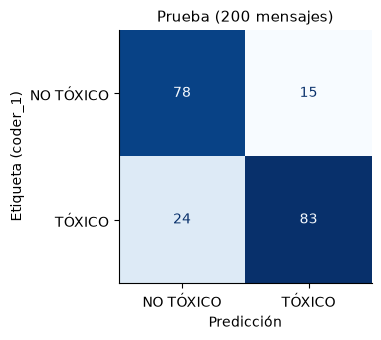

In [20]:
## Evaluación final en la prueba y referencia humana en los mismos mensajes
mejor = busqueda.best_estimator_
pred_test = mejor.predict(X_test)
f1_test = f1_score(y_test, pred_test, average="macro")
f1_humano = f1_score(y_test, protestas["coder_2"].to_numpy()[idx_test], average="macro")
print(f"Mejor modelo: {type(mejor.named_steps['modelo']).__name__} con "
      f"\"{mejor.named_steps['columna'].kw_args['columna']}\"")
print(f"F1 macro en prueba: {f1_test:.3f} | coder_2 frente a coder_1 en los mismos mensajes: {f1_humano:.3f}\n")
print(classification_report(y_test, pred_test, target_names=["NO TÓXICO", "TÓXICO"], digits=3))

fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["NO TÓXICO", "TÓXICO"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.grid(False)
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta (coder_1)")
ax.set_title("Prueba (200 mensajes)")
plt.tight_layout()
plt.show()

**Para recordar.**
- El F1 macro en prueba queda cerca de la estimación de la validación cruzada. Con 200 mensajes, la incertidumbre del F1 en prueba es de unos ± 0,03, así que una diferencia de ese tamaño con la CV no es preocupante.
- El modelo queda lejos de la referencia humana. Un clasificador de palabras sueltas no capta la ironía, el contexto ni a quién se dirige el mensaje. En la Sesión 13 compararemos con BERT y con LLMs.

## 5. Interpretación

### 5.1 Términos más informativos

**▶ En vivo.** En un modelo lineal, cada término tiene un coeficiente: los positivos empujan hacia TÓXICO y los negativos hacia NO TÓXICO. Mostramos los 15 de cada lado.

**Advertencia de contenido:** la lista de términos tóxicos incluye insultos.

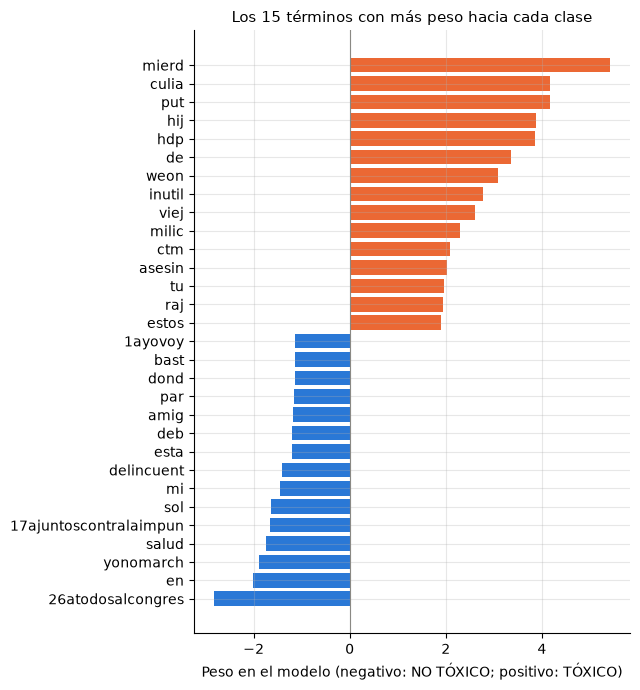

In [21]:
## Coeficientes del mejor modelo (o diferencia de log-probabilidades si es Naive Bayes)
vectorizador = mejor.named_steps["tfidf"]
clasificador = mejor.named_steps["modelo"]
terminos = vectorizador.get_feature_names_out()
if hasattr(clasificador, "coef_"):
    pesos = pd.Series(clasificador.coef_.ravel(), index=terminos)
else:
    pesos = pd.Series(clasificador.feature_log_prob_[1] - clasificador.feature_log_prob_[0], index=terminos)

extremos = pd.concat([pesos.nsmallest(15), pesos.nlargest(15).iloc[::-1]])
fig, ax = plt.subplots(figsize=(6.5, 7))
ax.barh(extremos.index, extremos.values, color=[AZUL if v < 0 else NARANJA for v in extremos.values])
ax.axvline(0, color=GRIS, lw=0.8)
ax.set_xlabel("Peso en el modelo (negativo: NO TÓXICO; positivo: TÓXICO)")
ax.set_title("Los 15 términos con más peso hacia cada clase")
plt.tight_layout()
plt.show()

**Para recordar.**
- Hacia TÓXICO pesan las raíces de insultos, muchos propios del habla chilena, y también palabras que se dirigen a alguien o lo señalan, como "tu" o "estos". Una lista de palabras vacías las habría eliminado.
- Hacia NO TÓXICO pesan varios *hashtags* de las protestas argentinas. Los mensajes de Argentina son menos tóxicos que los de Chile (sección 1), y el modelo aprendió ese **atajo del dominio**: los *hashtags* indican el país, no el tono. En otro contexto, sin esos *hashtags*, el atajo no sirve (sección 6).
- Leer los coeficientes es parte de la validación: permite detectar atajos que la métrica no muestra.

### 5.2 Regularización L1 frente a L2 (revisión autónoma)

Con L2 (la regularización por defecto) todos los términos conservan algún peso. Con **L1**, muchos coeficientes quedan exactamente en cero: el modelo selecciona términos, como el Lasso. Esta sección reemplaza la regresión Ridge y Lasso del notebook de 2025 (véase el Anexo).

In [22]:
## L1 frente a L2 en la regresión logística (raíces, unigramas)
## Nota de versión: desde scikit-learn 1.8, L1 se pide con l1_ratio=1 (penalty está obsoleto);
## en versiones anteriores (como la de Colab) se pide con penalty="l1"
penalizacion_l1 = {"l1_ratio": 1.0} if version_al_menos("scikit-learn", "1.8") else {"penalty": "l1"}
filas = []
for nombre, extra in [("L2", {}), ("L1", penalizacion_l1)]:
    for C in [1, 10, 100]:
        modelo = LogisticRegression(C=C, solver="liblinear", max_iter=2000, random_state=86, **extra)
        r = cross_validate(pipeline_texto(modelo, "raiz"), X_train, y_train, cv=cv5,
                           scoring="f1_macro", return_estimator=True)
        no_cero = np.mean([(e.named_steps["modelo"].coef_ != 0).sum() for e in r["estimator"]])
        total = np.mean([len(e.named_steps["tfidf"].vocabulary_) for e in r["estimator"]])
        filas.append({"penalización": nombre, "C": C, "F1 macro (CV)": r["test_score"].mean(),
                      "términos con peso": no_cero, "términos en total": total})
pd.DataFrame(filas).round(3)

,penalización,C,F1 macro (CV),términos con peso,términos en total
0,L2,1,0.783,2637.4,2637.4
1,L2,10,0.800,2637.4,2637.4
2,L2,100,0.790,2637.4,2637.4
3,L1,1,0.750,25.6,2637.4
4,L1,10,0.786,277.4,2637.4
5,L1,100,0.783,352.8,2637.4


**Para recordar.**
- Con L1 y C pequeño, el modelo usa solo una pequeña fracción del vocabulario. Pierde algo de F1, pero queda una lista corta de términos que se puede leer.
- Al subir C (menos regularización), L1 incorpora más términos y se acerca a L2.

### 5.3 Análisis de errores

**▶ En vivo.** Leemos los mensajes de prueba mal clasificados: primero los **falsos positivos** (no tóxicos clasificados como tóxicos) y luego los **falsos negativos**, ordenados por la seguridad del modelo. La columna `coder_2` muestra si el segundo codificador estaba de acuerdo con la etiqueta.

**Advertencia de contenido:** algunos mensajes contienen lenguaje ofensivo.

In [23]:
## Mensajes de prueba mal clasificados, ordenados por la seguridad del modelo
puntaje = mejor.decision_function(X_test) if hasattr(mejor, "decision_function") else mejor.predict_proba(X_test)[:, 1]
errores = pd.DataFrame({
    "mensaje (normalizado)": X_test["texto"].to_numpy(),
    "coder_1": y_test,
    "coder_2": protestas["coder_2"].to_numpy()[idx_test],
    "predicción": pred_test,
    "puntaje": puntaje,
})
errores = errores[errores["coder_1"] != errores["predicción"]]
print(f"Errores en prueba: {len(errores)} de {len(y_test)} | "
      f"falsos positivos: {(errores['predicción'] == 1).sum()} | falsos negativos: {(errores['predicción'] == 0).sum()}")
print(f"Desacuerdo entre codificadores: {(errores['coder_1'] != errores['coder_2']).mean():.0%} de los errores, "
      f"frente a {(protestas['coder_1'] != protestas['coder_2']).mean():.1%} en todo el conjunto")

pd.set_option("display.max_colwidth", 160)
falsos_positivos = errores[errores["predicción"] == 1].sort_values("puntaje", ascending=False).head(5)
falsos_negativos = errores[errores["predicción"] == 0].sort_values("puntaje").head(5)
pd.concat([falsos_positivos, falsos_negativos]).round(2)

Errores en prueba: 39 de 200 | falsos positivos: 15 | falsos negativos: 24
Desacuerdo entre codificadores: 5% de los errores, frente a 2.8% en todo el conjunto


,mensaje (normalizado),coder_1,coder_2,predicción,puntaje
67,"@usuario @usuario @usuario pregunta a tu gobierno que no quieren ver la realidad de la calle, no queremos maquillajes, que remos nuevaconstitucion entendés?...",0,0,1,1.18
64,@usuario y cuantxs muertxs? a cuantxs hirieron? háganse cargo de su brutalidad! renunciapiñera nosestanmatando estopasaenchile,0,0,1,1.06
35,@usuario @usuario @usuario el mejor comentario de los que están aquí 👍. que se vayan todos quesevayantodos,0,0,1,1.02
145,"@usuario si piñera renuncia y le pide la renuncia a todos sus ministros,le subrogaría el presidente del senado;a falta de éste,el presidente de la cámara de...",0,0,1,0.75
33,"@usuario no son de fiar, los yankys olvidando a los maquis españoles en la montaña, traicionando a los kurdos, no son de fiar con sus milicos pinochetistas ...",0,0,1,0.70
123,26atodosalcongreso pero che no se cansan de ser idiotas,1,1,0,-1.43
170,qué placer es escuchar a los kirnerolos mariconeando por la marcha 17aporlarepublica 17ajuntoscontralaimpunidad,1,1,0,-1.05
124,para allá va chile con los comunistas en el poder gobiernodepayasos,1,1,0,-1.02
15,@usuario @usuario que quilombo se te va a armar 26atodosalcongreso traidor a la patria!!! hdrmp!!!,1,1,0,-0.98
24,"políticos fachos llenándose la boca de palabras sobre qué apoyan la causa siendo que nacieron en cuna de oro, no tienen ni idea de cómo es la educación, tra...",1,1,0,-0.88


**Para recordar.**
- En casi todos los errores **los dos codificadores coincidían**: son pocos los mensajes ambiguos para las personas. Los errores son del modelo, no de la etiqueta.
- **Falsos positivos:** críticas políticas duras, sin insultos, con palabras que el modelo asocia a la toxicidad. El modelo confunde el tema con el tono.
- **Falsos negativos:** insultos abreviados, apodos despectivos o palabras poco frecuentes que el modelo vio pocas veces o nunca en el entrenamiento, y mensajes cuya toxicidad no está en una palabra sino en el conjunto.
- Leer los errores sugiere mejoras concretas: más datos de cierto tipo, otra representación, revisar el libro de códigos. Es el principio de **validar** de Grimmer y Stewart (2013).

## 6. Fuera del dominio: la Convención Constitucional

**▶ En vivo.** El segundo conjunto, `toxicity-Constitution-ES` (Hugging Face, CC BY 4.0), es un patrón oro del mismo proyecto: **1.000 mensajes** de Twitter de 2021 y 2022 sobre la primera Convención Constitucional de Chile (la elección de sus integrantes, la redacción y el plebiscito), con la misma codificación binaria por dos codificadores. La muestra también está balanceada por estratos de un puntaje automático de toxicidad.

Aplicamos el **mismo modelo final**, entrenado solo con mensajes de protestas, sin reajustarlo.

In [24]:
## Cargar y preparar el conjunto de la Convención con la misma función
convencion = pd.read_csv(URL_HF.format("toxicity-Constitution-ES", "goldstd_Convention.csv"))
X_conv = preparar(convencion["text"])
y_conv = convencion["coder_1"].to_numpy()
print(f"{len(convencion):,} mensajes | tóxicos (coder_1): {y_conv.mean():.1%} | "
      f"con mención a otra cuenta: {convencion['text'].str.contains('@').mean():.0%} | "
      f"con hashtag: {convencion['text'].str.contains('#').mean():.0%}")
print(f"κ de Cohen entre codificadores: {cohen_kappa_score(convencion['coder_1'], convencion['coder_2']):.3f} "
      f"(protestas: {cohen_kappa_score(protestas['coder_1'], protestas['coder_2']):.3f})")

## El modelo de protestas, aplicado a la Convención
pred_conv = mejor.predict(X_conv)
## Referencia: el mismo pipeline, entrenado y evaluado con validación cruzada dentro de la Convención
dentro = cross_validate(clone(mejor), X_conv, y_conv, cv=cv5, scoring="f1_macro")

pd.DataFrame({
    "F1 macro": [
        f1_test,
        f1_score(y_conv, pred_conv, average="macro"),
        dentro["test_score"].mean(),
        f1_score(y_conv, convencion["coder_2"], average="macro"),
    ]
}, index=[
    "Protestas → protestas (prueba, sección 4.4)",
    "Protestas → Convención (fuera del dominio)",
    "Convención → Convención (CV 5 pliegues, mismo pipeline)",
    "Referencia humana en la Convención (coder_2 frente a coder_1)",
]).round(3)

1,000 mensajes | tóxicos (coder_1): 65.1% | con mención a otra cuenta: 100% | con hashtag: 3%
κ de Cohen entre codificadores: 0.654 (protestas: 0.944)


,F1 macro
"Protestas → protestas (prueba, sección 4.4)",0.805
Protestas → Convención (fuera del dominio),0.687
"Convención → Convención (CV 5 pliegues, mismo pipeline)",0.703
Referencia humana en la Convención (coder_2 frente a coder_1),0.826


In [25]:
## ¿Dónde falla fuera del dominio?
print(classification_report(y_conv, pred_conv, target_names=["NO TÓXICO", "TÓXICO"], digits=3))

              precision    recall  f1-score   support

   NO TÓXICO      0.551     0.734     0.629       349
      TÓXICO      0.826     0.679     0.745       651

    accuracy                          0.698      1000
   macro avg      0.688     0.706     0.687      1000
weighted avg      0.730     0.698     0.705      1000



**Para recordar.**
- Fuera del dominio el F1 macro **cae** respecto de la prueba en protestas. El modelo no aprendió "la toxicidad", sino la toxicidad de los mensajes de protestas de 2019 y 2020. Pierde sobre todo mensajes tóxicos (su recall baja).
- Parte de la caída es del dominio: casi todos los mensajes de la Convención son **respuestas** a otras cuentas, con otros temas y otras palabras, y la proporción de tóxicos es mayor.
- Parte es de la tarea: en la Convención **también las personas coinciden menos** (κ mucho menor). Por eso entrenar con datos de la Convención apenas mejora el resultado.
- Antes de usar un clasificador en otro contexto, hay que **volver a validarlo** con una muestra codificada de ese contexto.

## 7. Ejercicios para la casa

1. ***Stemming* frente a lematización.** Cambien el preprocesamiento del mejor *pipeline* entre Snowball y la lematización de spaCy. ¿Cambia el F1 macro en validación? ¿Y el tamaño del vocabulario?
2. **Palabras vacías como hiperparámetro.** Entrenen el modelo con y sin eliminar palabras vacías (prueben también conservando "no" y "nunca"). ¿Qué pasa con los errores en mensajes con negación?
3. **n-gramas y `min_df`.** Prueben unigramas frente a unigramas + bigramas, con distintos `min_df`, dentro de la búsqueda de hiperparámetros.
4. **Desbalance.** Prueben `class_weight="balanced"` y comparen precisión y recall de la clase tóxica.

Usen siempre la validación cruzada dentro del entrenamiento (`X_train`, `y_train`, `cv5`) para comparar; la prueba ya se usó.

In [26]:
## Plantilla para los ejercicios 1 y 2: descomente y complete
# for columna in ["raiz", "lema"]:
#     pipe = pipeline_texto(LinearSVC(random_state=86), columna, sublinear_tf=True)
#     r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring="f1_macro")
#     print(columna, round(r["test_score"].mean(), 3))
#
# ## Ejercicio 2: mensajes de entrenamiento con negación, para revisar sus errores con cross_val_predict
# con_negacion = X_train["texto"].str.contains(r"\b(?:no|nunca)\b")
# print(f'Mensajes con "no" o "nunca": {con_negacion.sum()}')

In [27]:
## Plantilla para los ejercicios 3 y 4: descomente y complete
# espacio_ej = {
#     "tfidf__ngram_range": [(1, 1), (1, 2)],
#     "tfidf__min_df": [1, 2, 5],
#     "modelo__C": loguniform(0.01, 10),
#     "modelo__class_weight": [None, "balanced"],
# }
# busqueda_ej = RandomizedSearchCV(pipeline_texto(LinearSVC(random_state=86), "raiz"), espacio_ej, n_iter=20,
#                                  cv=cv5, scoring="f1_macro", random_state=86, n_jobs=N_PROCESOS)
# busqueda_ej.fit(X_train, y_train)
# print(busqueda_ej.best_score_, busqueda_ej.best_params_)

## Anexo: Ridge y Lasso con una etiqueta binaria (notebook de 2025)

El notebook `6_regressions_TADA` de 2025 ajustaba una **regresión** Ridge y una Lasso a la etiqueta 0/1, con TF-IDF de 1.000 términos (unigramas y bigramas, sin palabras vacías de NLTK), y obtenía un R² de 0,34 con Ridge y de −0,004 con Lasso (`alpha=0.1`). Reproducimos la idea con nuestra partición para ver qué pasaba.

In [28]:
## Ridge y Lasso sobre la etiqueta 0/1, como en 2025 (aquí con el texto normalizado de 2026)
tfidf_2025 = {"max_features": 1000, "ngram_range": (1, 2), "stop_words": sorted(STOP_NLTK)}
for nombre, modelo in [("Ridge (alpha = 1)", Ridge(alpha=1.0)), ("Lasso (alpha = 0,1)", Lasso(alpha=0.1))]:
    pipe = pipeline_texto(modelo, "texto", **tfidf_2025).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"{nombre}: R² = {r2_score(y_test, pred):.3f} | coeficientes distintos de cero: "
          f"{(pipe.named_steps['modelo'].coef_ != 0).sum()} de 1000 | "
          f"predicciones entre {pred.min():.2f} y {pred.max():.2f}")

Ridge (alpha = 1): R² = 0.334 | coeficientes distintos de cero: 1000 de 1000 | predicciones entre -0.21 y 1.42
Lasso (alpha = 0,1): R² = -0.000 | coeficientes distintos de cero: 0 de 1000 | predicciones entre 0.53 y 0.53


**Para recordar.**
- Con `alpha=0.1`, el Lasso pone **todos** los coeficientes en cero: predice la misma proporción para todos los mensajes. Por eso su R² era prácticamente cero. Los valores TF-IDF son pequeños, y un `alpha` útil para estos datos es mucho menor.
- Ridge da predicciones continuas, que incluso pueden salir del intervalo [0, 1], y el R² no es una métrica de clasificación.
- Para una etiqueta binaria, la regresión logística con L1 o L2 (sección 5.2) hace lo mismo que Ridge y Lasso, pero con probabilidades y con las métricas de clasificación del curso.

**Para recordar (síntesis de la sesión).**
- El texto se vuelve datos con decisiones: tokenización, normalización, palabras vacías, *stemming* o lematización, n-gramas y ponderación TF-IDF. Cada una **se valida** como un hiperparámetro.
- Todo lo que aprende de los datos (vocabulario, idf, modelo) va dentro del *pipeline* y se ajusta solo con el entrenamiento.
- Los modelos lineales sobre TF-IDF son una línea base fuerte y legible: sus coeficientes y sus errores dicen qué aprendió el modelo.
- La referencia es la codificación humana, y el dominio importa: un modelo se vuelve a validar antes de usarlo en otro contexto.
- **Próxima sesión (S13):** modelos semi-supervisados y clasificación con BERT y LLMs, con estos mismos datos.

**Referencias**
- Bird, S., Klein, E. y Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly.
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37–46.
- González-Bustamante, B. (2024). Benchmarking LLMs in political content text-annotation: Proof-of-concept with toxicity and incivility data. arXiv:2409.09741.
- Grimmer, J. y Stewart, B. M. (2013). Text as data: The promise and pitfalls of automatic content analysis methods for political texts. *Political Analysis*, 21(3), 267–297.
- Honnibal, M., Montani, I., Van Landeghem, S. y Boyd, A. (2020). *spaCy: Industrial-strength natural language processing in Python*. Zenodo. https://doi.org/10.5281/zenodo.1212303
- Hvitfeldt, E. y Silge, J. (2022). *Supervised Machine Learning for Text Analysis in R*. CRC Press. https://smltar.com
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Porter, M. F. (2001). *Snowball: A language for stemming algorithms*. https://snowballstem.org